# PCA from scratch
In this notebook, I explore Principal Component Analysis (PCA) from both a mathematical and computational perspective.
The goal is to build a deep understanding of:
- the geometric intuition behind PCA (projections and varaince)
- the underlying linear algebra concepts (covariance, eigenvalues, eigenvectors)
- and how to implement PCA step by step using Numpy
rather than relying on libraries, I will implement PCA from scratch to better understand how dimensionality reduction works in pratice.

## Objectives
- Understand projections and their role in dimensionality reduction
- Connect variance maximization with information preservation
- Derive PCA using the covariance matrix
- Implement PCA step by step
- Visualize the transformation of data
## Approach
1. Center the data
2. Compute the covariance matric
3. Extract eigenvalues and eigenvectors
4. Sort compenents by explained variance
5. Project data onto principal components

## Expected Outcome
By the end of this notebook, I should be able to:
- explain PCA intuively and mathematically 
- implement it from scratch
- interpret the results in terms of variance and data structure

0 ||Ax - λx|| = 0.0
1 ||Ax - λx|| = 0.0
erreur reconstruction: 4.440892098500626e-16
Projection:
 [[-2.12132034  0.        ]
 [-0.70710678  0.        ]
 [ 0.70710678  0.        ]
 [ 2.12132034  0.        ]]


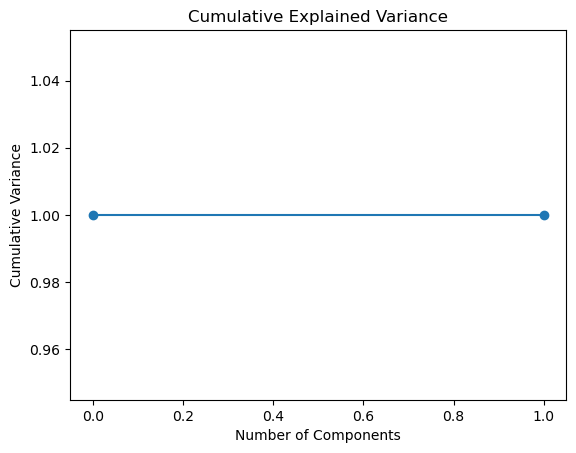

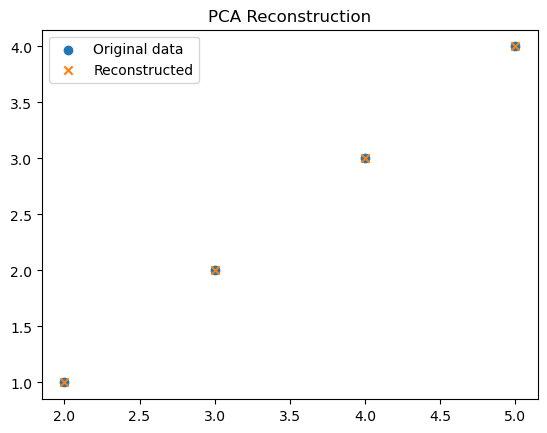

In [ ]:
import matplotlib.pyplot as plt
import numpy as np 

# X will be our data points
X = np.array([
    [2,1],
    [3,2],
    [4,3],
    [5,4]
])

# We calcul the mean
mean = np.mean(X, axis=0)

#Center the data
X_centered = X - mean

# Covariance matrice
# Numpy way
X_cov = np.cov(X_centered, rowvar=False) # we are using rowvar because columns are features rows are observations
# Manual way
X_cov_man = (1/ (X.shape[0]-1)) * (X_centered.T @ X_centered)

# Eigenvalues and eigenvectors
# Numpy
eigenvalues, eigenvectors = np.linalg.eigh(X_cov) # I can use eigh because i know that my matric is symmetric

""" 
Manual way AX 
def power_iteration(A, num_iters=100):
    n = A.shape[0]
    
    # Invitial random eigenvector
    b_k = np.random.rand(n)
    
    for _ in range(num_iters):
        # multiplication
        b_k1 = A @ b_k
        
        # normalisation
        b_k1_norm = np.linalg.norm(b_k1)
        b_k = b_k1 / b_k1_norm
    
    # Eigen values
    eigenvalue = b_k.T @ A @ b_k
    
    return eigenvalue, b_k
"""
for i in range(len(eigenvalues)):
    lam = eigenvalues[i]
    x = eigenvectors[:, i]
    lhs = X_cov @ x
    rhs = lam * x
    print(i, "||Ax - λx|| =", np.linalg.norm(lhs - rhs))
V = eigenvectors
Lambda = np.diag(eigenvalues)
A_recon = V @ Lambda @ V.T  
print("Reconstruction error:", np.linalg.norm(X_cov - A_recon))
A_recon = V @ Lambda @ V.T

# Sorting the eigenvalues and eigenvectors
idx = np.argsort(eigenvalues)[::-1]
eigenvalues = eigenvalues[idx]
eigenvectors = eigenvectors[:, idx]

# Projection
X_proj = X_centered @ eigenvectors
print("Projection:\n", X_proj)

# Dimension reduction
k = 1
W = eigenvectors[:, :k]
X_reduced = X_centered @ W

# Reconstruction
X_approx = X_reduced @ W.T + mean 

# Explained variance
explained_variance_ratio = eigenvalues / np.sum(eigenvalues)

# Plot the explained variance
cumulative_variance = np.cumsum(explained_variance_ratio)

fig, ax = plt.subplots()
ax.plot(cumulative_variance, marker='o')
ax.set_title("Cumulative Explained Variance")
ax.set_xlabel("Number of Components")
ax.set_ylabel("Cumulative Variance")
plt.show()

# PCA visualisation
plt.scatter(X[:,0], X[:,1], label="Original data")
plt.scatter(X_approx[:,0], X_approx[:,1], label="Reconstructed", marker='x')
plt.legend()
plt.title("PCA Reconstruction")
plt.show()